# Assistência do GPT e tempo até o merge de pull requests

**MCEQ 12576 – Projeto Final (PUC-Campinas)** · Rafael Roveri Pires e Felipe Nonato Leoneli

Análise confirmatória descrita no protocolo de 1 página (registro retrospectivo, redigido em 26/11/2026, depois desta análise). Estudo **observacional**, sem afirmações causais.

- **H0:** μA = μB · **H1 (unilateral):** μA < μB, em que A = PRs com GPT e B = PRs sem GPT
- **VD:** `time_to_merge_h`, o tempo até o merge em horas · **VI:** `is_gpt` (1 = com GPT, 0 = sem GPT)
- **Teste principal:** Mann-Whitney U unilateral, α = 0,05 · **Efeito:** Cliff's delta + diferença de medianas com IC de 95% (bootstrap)
- **Sensibilidade:** Welch unilateral sobre log(1 + horas), com d de Cohen

Fonte dos dados: Collante et al., *The Impact of Large Language Models (LLMs) on Code Review Process*, arXiv 2508.11034 (v2).
Repositório `acollant/GPT-Assistance-PR`, commit fixado abaixo.

In [1]:
from pathlib import Path
import hashlib
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05
SEED = 2026
N_BOOT = 10_000

COMMIT = "72df511069ee0255c44460839de55b69c9a5549a"  # versão fixada da base (acesso em 25/11/2026)
SHA256 = "a002720ff6c8ce8bd4a42e4ea94214deead2d0bd101c62b08bdc012f68b24610"  # hash do CSV baixado em 25/11/2026
URL = f"https://raw.githubusercontent.com/acollant/GPT-Assistance-PR/{COMMIT}/R/RQ1/at_resolution.csv"

BRUTO = Path("dados/brutos/at_resolution.csv")
LIMPO = Path("dados/limpos/prs_limpos.csv")
FIG = Path("figuras/boxplot_tempo_merge.png")
for p in (BRUTO, LIMPO, FIG):
    p.parent.mkdir(parents=True, exist_ok=True)

## 1. Download dos dados brutos
O CSV não é redistribuído neste repositório: ele é baixado da fonte original, no commit fixado. Os dados brutos nunca são editados: o SHA-256 confere se o arquivo local é o mesmo usado no artigo.

In [2]:
if not BRUTO.exists():
    urllib.request.urlretrieve(URL, BRUTO)
assert hashlib.sha256(BRUTO.read_bytes()).hexdigest() == SHA256, "CSV diferente do usado no artigo"
bruto = pd.read_csv(BRUTO)
print(bruto.shape)
bruto.head()

(2404, 9)


,project,pull_number,actor,project_age_month,no_commits,PR_size(SLOC),no_changed_files,time_to_merge_h,is_gpt
0,0atman_noboilerplate,48,0atman,16,5,742,40,7.889,1
1,1712n_dn-institute,293,evgenydmitriev,7,2,842,3,91.361,1
2,1Panel-dev_appstore,355,zhengkunwang223,6,3,96,11,388.156,0
3,3DStreet_3dstreet-editor,274,kfarr,14,6,222,12,14.106,1
4,6boris_awesome-golang-algorithm,732,6boris,62,1,93,3,918.679,0


## 2. Limpeza (regras do protocolo)
Remove apenas: tempo ausente, tempo negativo, `is_gpt` fora de {0, 1} e PRs duplicados (mesmo projeto e número). **Nenhum outlier é removido.**

In [3]:
df = bruto.copy()
log_limpeza = {"linhas brutas": len(df)}

df = df.dropna(subset=["time_to_merge_h", "is_gpt"])
log_limpeza["após remover tempo/grupo ausente"] = len(df)

df = df[df["time_to_merge_h"] >= 0]
log_limpeza["após remover tempo negativo"] = len(df)

df = df[df["is_gpt"].isin([0, 1])]
log_limpeza["após remover is_gpt inválido"] = len(df)

df = df.drop_duplicates(subset=["project", "pull_number"])
log_limpeza["após remover duplicados"] = len(df)

df["grupo"] = df["is_gpt"].map({1: "A: com GPT", 0: "B: sem GPT"})
df.to_csv(LIMPO, index=False)

for etapa, n in log_limpeza.items():
    print(f"{etapa:35s} {n:6d}")
print("linhas removidas no total:", len(bruto) - len(df))

linhas brutas                         2404
após remover tempo/grupo ausente      2404
após remover tempo negativo           2404
após remover is_gpt inválido          2404
após remover duplicados               2404
linhas removidas no total: 0


## 3. Estatística descritiva
VD por grupo e variáveis de controle por grupo (para checar o balanceamento do pareamento feito pelos autores).

In [4]:
a = df.loc[df["is_gpt"] == 1, "time_to_merge_h"].to_numpy()
b = df.loc[df["is_gpt"] == 0, "time_to_merge_h"].to_numpy()

def descreve(x):
    return pd.Series({"n": len(x), "média": x.mean(), "desvio": x.std(ddof=1),
                      "Q1": np.percentile(x, 25), "mediana": np.median(x),
                      "Q3": np.percentile(x, 75), "mín": x.min(), "máx": x.max()})

desc = pd.DataFrame({"A: com GPT": descreve(a), "B: sem GPT": descreve(b)}).T
print("Tempo até o merge (horas)")
desc.round(2)

Tempo até o merge (horas)


,n,média,desvio,Q1,mediana,Q3,mín,máx
A: com GPT,1368.0,194.64,800.15,1.49,20.84,124.27,0.0,24106.96
B: sem GPT,1036.0,286.39,792.64,7.91,51.71,217.92,0.0,13358.22


In [5]:
controles = ["PR_size(SLOC)", "no_commits", "no_changed_files", "project_age_month"]
df.groupby("grupo")[controles].median().round(1).rename_axis("mediana por grupo")

,PR_size(SLOC),no_commits,no_changed_files,project_age_month
mediana por grupo,,,,
A: com GPT,137.5,2.0,7.0,26.0
B: sem GPT,114.0,3.0,6.0,31.0


## 4. Figura
Boxplot em escala logarítmica, com os pontos visíveis (a escala log é necessária pela assimetria; está indicada no eixo).

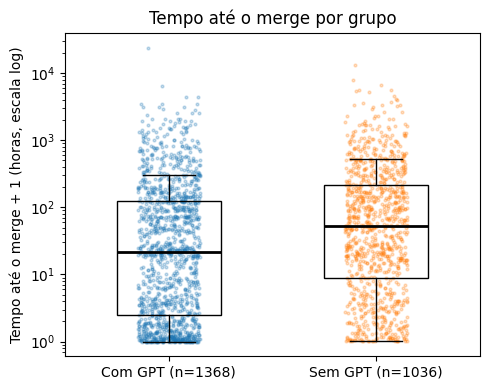

In [6]:
rng_plot = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(5, 4))
dados = [a + 1, b + 1]  # +1 h para permitir PRs com tempo 0 na escala log
ax.boxplot(dados, showfliers=False, widths=0.5, zorder=3, patch_artist=True,
           boxprops=dict(facecolor="none"), medianprops=dict(color="black", linewidth=2))
for i, x in enumerate(dados, start=1):
    ax.scatter(i + rng_plot.uniform(-0.15, 0.15, len(x)), x, s=4, alpha=0.25, zorder=1)
ax.set_yscale("log")
ax.set_xticks([1, 2], [f"Com GPT (n={len(a)})", f"Sem GPT (n={len(b)})"])
ax.set_ylabel("Tempo até o merge + 1 (horas, escala log)")
ax.set_title("Tempo até o merge por grupo")
fig.tight_layout()
fig.savefig(FIG, dpi=300)
plt.show()

## 5. Teste confirmatório: Mann-Whitney U unilateral
H1: tempos do grupo A tendem a ser menores que os do grupo B (`alternative='less'`).

In [7]:
mw = stats.mannwhitneyu(a, b, alternative="less")
cliff = 2 * mw.statistic / (len(a) * len(b)) - 1  # Cliff's delta = P(A>B) - P(A<B); negativo => A menor

rng = np.random.default_rng(SEED)
boot = (np.median(rng.choice(a, (N_BOOT, len(a))), axis=1)
        - np.median(rng.choice(b, (N_BOOT, len(b))), axis=1))
ic_low, ic_high = np.percentile(boot, [2.5, 97.5])
dif_med = np.median(a) - np.median(b)

print(f"U = {mw.statistic:.1f}, p (unilateral) = {mw.pvalue:.3g}")
print(f"Decisão com α = {ALPHA}: {'rejeita H0' if mw.pvalue < ALPHA else 'não rejeita H0'}")
print(f"Cliff's delta = {cliff:.3f}")
print(f"Diferença de medianas (A − B) = {dif_med:.2f} h, IC 95% bootstrap [{ic_low:.2f}; {ic_high:.2f}] h")

U = 571287.0, p (unilateral) = 1.84e-16
Decisão com α = 0.05: rejeita H0
Cliff's delta = -0.194
Diferença de medianas (A − B) = -30.87 h, IC 95% bootstrap [-42.30; -22.28] h


Referência usual para |Cliff's delta| (Romano et al., 2006): < 0,147 desprezível; < 0,33 pequeno; < 0,474 médio; ≥ 0,474 grande.

## 6. Análise de sensibilidade (prevista no protocolo): Welch sobre log(1 + horas)

In [8]:
la, lb = np.log1p(a), np.log1p(b)
welch = stats.ttest_ind(la, lb, equal_var=False, alternative="less")
d = (la.mean() - lb.mean()) / np.sqrt((la.var(ddof=1) + lb.var(ddof=1)) / 2)
ic = welch.confidence_interval(confidence_level=0.95)  # unilateral: limite inferior = -inf

print(f"t = {welch.statistic:.3f}, gl = {welch.df:.1f}, p (unilateral) = {welch.pvalue:.3g}")
print(f"d de Cohen (escala log) = {d:.3f}")
print(f"Diferença de médias em log(1+h) = {la.mean() - lb.mean():.3f}; limite superior unilateral 95% = {ic.high:.3f}")
print(f"Razão das médias geométricas de (1+h), A/B = {np.exp(la.mean() - lb.mean()):.2f}")

t = -8.270, gl = 2279.4, p (unilateral) = 1.12e-16
d de Cohen (escala log) = -0.340
Diferença de médias em log(1+h) = -0.744; limite superior unilateral 95% = -0.596
Razão das médias geométricas de (1+h), A/B = 0.47


## 7. Verificações automáticas
Garante que a análise rodou sobre os dados esperados.

In [9]:
assert set(df["is_gpt"].unique()) == {0, 1}
assert len(a) > 0 and len(b) > 0
assert len(a) + len(b) == len(df)
assert -1 <= cliff <= 1
assert ic_low <= ic_high
print("OK: verificações passaram")

OK: verificações passaram


## Análises exploratórias
Qualquer análise além das seções 5 e 6 deve ficar **abaixo desta linha** e ser relatada no artigo como exploratória.

Testes inferenciais no total: 9 (Mann-Whitney e Welch, previstos no protocolo; o Mann-Whitney por projeto, E1; e 6 Mann-Whitney por subgrupo, E2, com correção de Holm).

### E1. Projeto como unidade de análise (exploratória)
PRs do mesmo projeto não são independentes, e poucos projetos concentram muitos PRs. Aqui cada projeto entra uma vez por grupo, pela mediana do tempo até o merge dos seus PRs, e repetimos o Mann-Whitney unilateral e o Cliff's delta. Análise decidida depois de ver o resultado confirmatório, por isso exploratória.

In [10]:
for k, nome in ((1, "A: com GPT"), (0, "B: sem GPT")):
    cont = df.loc[df["is_gpt"] == k, "project"].value_counts()
    print(f"{nome}: {len(cont)} projetos; os 10 maiores somam {cont.head(10).sum() / cont.sum():.0%} dos PRs")
print("projetos com PRs nos dois grupos:", int((df.groupby("project")["is_gpt"].nunique() == 2).sum()))

por_proj = df.groupby(["project", "is_gpt"], as_index=False)["time_to_merge_h"].median()
pa = por_proj.loc[por_proj["is_gpt"] == 1, "time_to_merge_h"].to_numpy()
pb = por_proj.loc[por_proj["is_gpt"] == 0, "time_to_merge_h"].to_numpy()
mw_proj = stats.mannwhitneyu(pa, pb, alternative="less")
cliff_proj = 2 * mw_proj.statistic / (len(pa) * len(pb)) - 1

print(f"\nMediana das medianas por projeto: A = {np.median(pa):.2f} h (n = {len(pa)}), "
      f"B = {np.median(pb):.2f} h (n = {len(pb)})")
print(f"U = {mw_proj.statistic:.1f}, p (unilateral) = {mw_proj.pvalue:.3g}, Cliff's delta = {cliff_proj:.3f}")

A: com GPT: 358 projetos; os 10 maiores somam 52% dos PRs
B: sem GPT: 511 projetos; os 10 maiores somam 28% dos PRs
projetos com PRs nos dois grupos: 24

Mediana das medianas por projeto: A = 55.36 h (n = 358), B = 48.80 h (n = 511)
U = 92252.0, p (unilateral) = 0.585, Cliff's delta = 0.009


### E2. Subgrupos por características do PR e do projeto (exploratória)
Sugestão do professor (orientação de 26/11/2026): repetir a comparação com GPT × sem GPT dentro de subgrupos.
Cada variável é dividida na **mediana da amostra inteira** (baixo = ≤ mediana; alto = > mediana), um corte definido antes de olhar o tempo até o merge nos subgrupos:

- `no_commits`: número de commits do PR
- `no_changed_files`: número de arquivos alterados
- `project_age_month`: idade do projeto, em meses

Em cada um dos 6 subgrupos: Mann-Whitney unilateral (A < B), Cliff's delta e diferença de medianas com IC de 95% por bootstrap.
Como são 6 testes, os p-valores são corrigidos por **Holm** (controle do erro familiar com α = 0,05). Exigimos n ≥ 30 por grupo em cada subgrupo.

In [11]:
def holm(pvalores):
    """p-valores ajustados por Holm-Bonferroni, na ordem original."""
    p = np.asarray(pvalores, dtype=float)
    m = len(p)
    ordem = np.argsort(p)
    ajust = np.empty(m)
    acumulado = 0.0
    for posto, i in enumerate(ordem):
        acumulado = max(acumulado, min(1.0, (m - posto) * p[i]))
        ajust[i] = acumulado
    return ajust

# auto-teste com exemplo calculado à mão: p = [0,01; 0,04; 0,03] -> [0,03; 0,06; 0,06]
assert np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])

In [12]:
VARS_SUB = {"no_commits": "Commits", "no_changed_files": "Arquivos alterados", "project_age_month": "Idade do projeto (meses)"}
N_MIN = 30
rng_sub = np.random.default_rng(SEED)

linhas = []
for var, rotulo in VARS_SUB.items():
    corte = df[var].median()
    for nivel, mascara in (("baixo", df[var] <= corte), ("alto", df[var] > corte)):
        sub = df[mascara]
        xa = sub.loc[sub["is_gpt"] == 1, "time_to_merge_h"].to_numpy()
        xb = sub.loc[sub["is_gpt"] == 0, "time_to_merge_h"].to_numpy()
        assert len(xa) >= N_MIN and len(xb) >= N_MIN, f"{var} {nivel}: n abaixo de {N_MIN}"
        teste = stats.mannwhitneyu(xa, xb, alternative="less")
        bt = (np.median(rng_sub.choice(xa, (N_BOOT, len(xa))), axis=1)
              - np.median(rng_sub.choice(xb, (N_BOOT, len(xb))), axis=1))
        lo, hi = np.percentile(bt, [2.5, 97.5])
        linhas.append({
            "variável": rotulo,
            "subgrupo": f"{nivel} ({'≤' if nivel == 'baixo' else '>'} {corte:g})",
            "n_A": len(xa), "n_B": len(xb),
            "mediana_A_h": np.median(xa), "mediana_B_h": np.median(xb),
            "dif_medianas_h": np.median(xa) - np.median(xb), "ic95_inf_h": lo, "ic95_sup_h": hi,
            "cliffs_delta": 2 * teste.statistic / (len(xa) * len(xb)) - 1,
            "U": teste.statistic, "p_unilateral": teste.pvalue,
        })

sub_res = pd.DataFrame(linhas)
sub_res["p_holm"] = holm(sub_res["p_unilateral"])
sub_res["decisão (Holm, α = 0,05)"] = np.where(sub_res["p_holm"] < ALPHA, "rejeita H0", "não rejeita H0")

assert len(sub_res) == 6
assert (sub_res["p_holm"] >= sub_res["p_unilateral"]).all()
assert sub_res.groupby("variável")[["n_A", "n_B"]].sum().eq([len(a), len(b)]).all().all()  # subgrupos cobrem todos os PRs

RES_SUB = Path("resultados/subgrupos_E2.csv")
RES_SUB.parent.mkdir(exist_ok=True)
sub_res.to_csv(RES_SUB, index=False, float_format="%.4g")  # 4 algarismos significativos: mantém p-valores muito pequenos
sub_res.round({"mediana_A_h": 2, "mediana_B_h": 2, "dif_medianas_h": 2, "ic95_inf_h": 2, "ic95_sup_h": 2,
               "cliffs_delta": 3, "U": 1}).style.format({"p_unilateral": "{:.2e}", "p_holm": "{:.2e}"}, precision=2)

,variável,subgrupo,n_A,n_B,mediana_A_h,mediana_B_h,dif_medianas_h,ic95_inf_h,ic95_sup_h,cliffs_delta,U,p_unilateral,p_holm,"decisão (Holm, α = 0,05)"
0,Commits,baixo (≤ 2),712,516,3.46,17.55,-14.09,-16.46,-10.54,-0.24,138761.50,1.19e-13,5.96e-13,rejeita H0
1,Commits,alto (> 2),656,520,69.78,119.61,-49.83,-77.99,-25.81,-0.16,143848.00,1.94e-06,3.88e-06,rejeita H0
2,Arquivos alterados,baixo (≤ 7),692,578,3.80,20.19,-16.39,-21.15,-12.78,-0.28,142917.50,9.08e-19,5.45e-18,rejeita H0
3,Arquivos alterados,alto (> 7),676,458,69.96,137.28,-67.31,-94.16,-34.10,-0.17,127719.50,2.79e-07,8.38e-07,rejeita H0
4,Idade do projeto (meses),baixo (≤ 29),740,500,8.48,32.40,-23.92,-40.33,-12.91,-0.23,141440.00,9.49e-13,3.79e-12,rejeita H0
5,Idade do projeto (meses),alto (> 29),628,536,45.65,69.79,-24.14,-49.35,3.43,-0.12,148538.00,2.72e-04,2.72e-04,rejeita H0


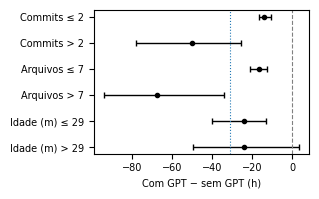

In [13]:
# Figura 2 do artigo: tamanho pensado para 1 coluna do template ACM (3,4 pol.), fonte em tamanho real
FIG_SUB = Path("figuras/efeito_subgrupos.png")
plt.rcParams.update({"font.size": 7})
curto = {"Commits": "Commits", "Arquivos alterados": "Arquivos", "Idade do projeto (meses)": "Idade (m)"}
fig, ax = plt.subplots(figsize=(3.2, 2.0))
y = np.arange(len(sub_res))[::-1]
ax.errorbar(sub_res["dif_medianas_h"], y,
            xerr=[sub_res["dif_medianas_h"] - sub_res["ic95_inf_h"], sub_res["ic95_sup_h"] - sub_res["dif_medianas_h"]],
            fmt="o", color="black", markersize=3, capsize=2, linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(dif_med, color="tab:blue", linestyle=":", linewidth=0.8)  # amostra inteira (explicado na legenda do artigo)
ax.set_yticks(y, [f"{curto[v]} {s.split('(')[1].rstrip(')')}" for v, s in zip(sub_res["variável"], sub_res["subgrupo"])])
ax.set_xlabel("Com GPT − sem GPT (h)")
fig.tight_layout()
fig.savefig(FIG_SUB, dpi=300, bbox_inches="tight")
plt.show()

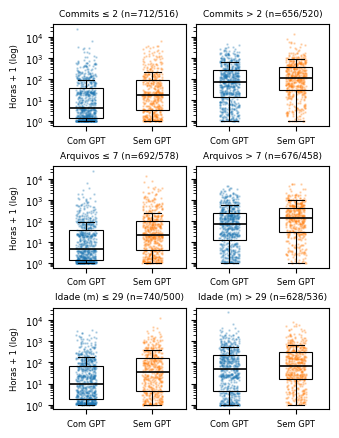

In [14]:
# Figura 3 do artigo: boxplots por subgrupo (mesma leitura da Figura 1), 1 coluna do template ACM
FIG_BOX_SUB = Path("figuras/boxplot_subgrupos.png")
rng_box = np.random.default_rng(SEED)
fig, eixos = plt.subplots(3, 2, figsize=(3.4, 4.4), sharey=True)
for linha, (var, rotulo) in zip(eixos, VARS_SUB.items()):
    corte = df[var].median()
    for ax, (nivel, mascara) in zip(linha, (("≤", df[var] <= corte), (">", df[var] > corte))):
        sub = df[mascara]
        dados_sub = [sub.loc[sub["is_gpt"] == k, "time_to_merge_h"].to_numpy() + 1 for k in (1, 0)]  # +1 h para a escala log
        ax.boxplot(dados_sub, showfliers=False, widths=0.5, zorder=3, patch_artist=True,
                   boxprops=dict(facecolor="none", linewidth=0.8), whiskerprops=dict(linewidth=0.8),
                   capprops=dict(linewidth=0.8), medianprops=dict(color="black", linewidth=1.2))
        for j, x in enumerate(dados_sub, start=1):
            ax.scatter(j + rng_box.uniform(-0.15, 0.15, len(x)), x, s=0.6, alpha=0.25, zorder=1,
                       color="tab:blue" if j == 1 else "tab:orange")
        ax.set_yscale("log")
        ax.set_xticks([1, 2], ["Com GPT", "Sem GPT"], fontsize=6)
        ax.set_title(f"{curto[rotulo]} {nivel} {corte:g} (n={len(dados_sub[0])}/{len(dados_sub[1])})", fontsize=6.5)
for linha in eixos:
    linha[0].set_ylabel("Horas + 1 (log)", fontsize=6)
fig.tight_layout(h_pad=0.6, w_pad=0.6)
fig.savefig(FIG_BOX_SUB, dpi=300, bbox_inches="tight")
plt.show()
plt.rcParams.update({"font.size": 10})

## Resultados gravados
Grava em `resultados/` os números do artigo, para conferência sem reexecutar o notebook.

In [15]:
import json

RES = Path("resultados")
RES.mkdir(exist_ok=True)
desc.round(2).to_csv(RES / "tabela1_descritiva.csv")
resultados = {
    "fonte": {"url": URL, "sha256": SHA256, "acesso": "2026-11-25"},
    "limpeza": log_limpeza,
    "n": {"A_com_gpt": len(a), "B_sem_gpt": len(b)},
    "confirmatorio_mann_whitney": {"U": float(mw.statistic), "p_unilateral": float(mw.pvalue),
                                   "cliffs_delta": float(cliff), "dif_medianas_h": float(dif_med),
                                   "ic95_bootstrap_h": [float(ic_low), float(ic_high)]},
    "sensibilidade_welch_log": {"t": float(welch.statistic), "gl": float(welch.df),
                                "p_unilateral": float(welch.pvalue), "d_cohen": float(d),
                                "razao_medias_geometricas": float(np.exp(la.mean() - lb.mean()))},
    "exploratoria_por_projeto": {"n_projetos_A": len(pa), "n_projetos_B": len(pb),
                                 "U": float(mw_proj.statistic), "p_unilateral": float(mw_proj.pvalue),
                                 "cliffs_delta": float(cliff_proj)},
    "exploratoria_subgrupos": "ver resultados/subgrupos_E2.csv",
    "testes_inferenciais": 9,
}
(RES / "resultados.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False), encoding="utf-8")
print("gravado em", RES.resolve())

gravado em C:\Users\Administrator\Desktop\Faculdade\mceq-gpt-tempo-merge\resultados
